# Visual Perturbation & Noise Sensitivity Probes

Evaluates how visual perturbations (blur and additive Gaussian noise) affect latent stability and downstream physical-state probe $R^2$ across static and transitioned representations for AE vs. V-JEPA.

In [1]:
# import sys
from pathlib import Path

import torch
from torch import nn
import torch.nn.functional as F

import torchvision.transforms.v2 as v2

import numpy as np


import matplotlib.pyplot as plt

# parent_dir = str(Path('../..').resolve())
# if parent_dir not in sys.path:
#     sys.path.append(parent_dir)
# from dmc_dataset.dataset import get_dataset


from rvsablation.ae import FSQ_VideoVAE
from rvsablation.core import _TransformerStack
from rvsablation.jepa import FSQ_V_JEPA
from rvsablation.utils import get_3d_sincos_pos_embed, read_config, seed_everything, get_dataset
rng = seed_everything(42)
from torchmetrics.image import StructuralSimilarityIndexMeasure
from torchmetrics.regression import R2Score

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_RUNS = {
    'ae': 'fsq_videovae_run_1', 
    'jepa': 'fsq_v_jepa_run_1',
}

SSIM = StructuralSimilarityIndexMeasure().to(DEVICE)
R2UN_AE = R2Score().to(DEVICE)
R2P_AE = R2Score().to(DEVICE)
R2UNPT_AE = R2Score().to(DEVICE)
R2PPT_AE = R2Score().to(DEVICE)
R2UN_JEPA = R2Score().to(DEVICE)
R2P_JEPA = R2Score().to(DEVICE)
R2UNPT_JEPA = R2Score().to(DEVICE)
R2PPT_JEPA = R2Score().to(DEVICE)

dssds, testset, _, _ = get_dataset(
    rng=rng,
    root='../data/walker_trajs_h5/data.h5',
    sample_num_frames=10,
    sample_num_clips=12,
    data_num_traj=25000,
    data_num_frames=100,
)

NUM_SAMPLES = 500

AE_VAR = torch.tensor([[[8.254, 7.391, 6.865, 2.122, 2.075, 2.111]]])
JEPA_VAR = torch.tensor([[[6.216, 6.483, 6.381, 1.902, 1.83, 1.91]]])

def draw_clip(x: torch.tensor):
    fig, axs = plt.subplots(1, 8, figsize=(20, 10))
    tpi = v2.ToPILImage()
    for i in range(x.shape[1]):
        axs[i].imshow(tpi(x[0, i]), vmin=0, vmax=255, cmap="grey")
        axs[i].axis("off")

    plt.show()

🌱 Global seed set to 42


In [6]:
len(dssds) + len(testset), 12 * 25000

(300000, 300000)

In [2]:
class WindowTransitionProbe(nn.Module):
    def __init__(self, spatial_grid_size, temporal_grid_size, latent_dim, action_dim, hidden_dim, depth, attention_dim, attention_num_heads):
        super().__init__()
        self.latent_proj = nn.Linear(latent_dim, hidden_dim, bias=False)
        self.action_proj = nn.Linear(action_dim, hidden_dim, bias=False)
        self.out_proj = nn.Linear(hidden_dim, latent_dim, bias=False)
        self.stack = _TransformerStack(hidden_dim, depth, attention_dim, attention_num_heads)
        pos = get_3d_sincos_pos_embed(hidden_dim, temporal_grid_size, spatial_grid_size)
        self.register_buffer('pos', pos.unsqueeze(0), persistent=False)

    def forward(self, x, action):
        x = self.latent_proj(x)
        action = self.action_proj(action).unsqueeze(1)
        return self.out_proj(self.stack(x + action + self.pos, attn_mask=None))

# Visual Perturbation Studies

## 1. Load Encoders, Transition Models & State Probes

In [3]:
def load_model_pair(model_type: str, run_name, sample_actions):
    print(f"Loading for {run_name}:")
    run_dir = Path("..") / f'{model_type}_runs' / run_name

    model_config = read_config(run_dir / 'confs' / 'model_config.json')

    encoder_class = FSQ_VideoVAE if model_type == "ae" else FSQ_V_JEPA
    encoder = encoder_class(**model_config)
    print(f"\tEncoder: {encoder.load_state_dict(torch.load(run_dir / 'weights' / 'model_4.9m.pt', map_location=DEVICE, weights_only=True))}")
    encoder = encoder.to(DEVICE).eval()

    transition_model = WindowTransitionProbe(
        spatial_grid_size=encoder.encoder.spatial_grid_size,
        temporal_grid_size=encoder.encoder.temporal_grid_size,
        latent_dim=model_config["fsq_dim"],
        action_dim=sample_actions.shape[-1],
        hidden_dim=384, depth=6, attention_dim=384, attention_num_heads=6,
    ).to(DEVICE)
    print(f"\tTransition model: {transition_model.load_state_dict(torch.load(run_dir / 'transition_window' / 'transition_window_best.pt', map_location=DEVICE, weights_only=True))}")

    state_probe_sd = torch.load(run_dir / 'state_probe' / 'linear_probe.pt', map_location=DEVICE, weights_only=True)
    sp_out, sp_in = state_probe_sd['weight'].shape
    state_probe = nn.Linear(sp_in, sp_out).to(DEVICE)
    print(f"\tLinear state probe: {state_probe.load_state_dict(state_probe_sd)}")

    var = AE_VAR if model_type == "ae" else JEPA_VAR
    r2 = (R2UN_AE, R2P_AE, R2UNPT_AE, R2PPT_AE) if model_type == "ae" else (R2UN_JEPA, R2P_JEPA, R2UNPT_JEPA, R2PPT_JEPA)

    return encoder, transition_model, state_probe, var.to(DEVICE), r2[0], r2[1], r2[2], r2[3]

fs, sample_actions, *_ = testset[0]
fs_a = fs[:-2]
sample_actions_a = sample_actions[:-2]

fs_b = fs[2:]
sample_actions_b = sample_actions[2:]

model_pairs = {
    model_type: load_model_pair(model_type, run_name, sample_actions) # sample actions is only used to get the dimension of the actions
    for model_type, run_name in MODEL_RUNS.items()
}

Loading for fsq_videovae_run_1:
	Encoder: <All keys matched successfully>
	Transition model: <All keys matched successfully>
	Linear state probe: <All keys matched successfully>
Loading for fsq_v_jepa_run_1:
	Encoder: <All keys matched successfully>
	Transition model: <All keys matched successfully>
	Linear state probe: <All keys matched successfully>


In [4]:
PERTURBATION_A = v2.Compose([
    v2.GaussianBlur(11, sigma=(0.01, 0.01)),
    # T.ColorJitter(hue=(0, 0.3))
])
def perturb_clip(x: torch.tensor, perturbation: v2.Compose, sigma: float):
    epsilon = torch.randn_like(x) * sigma
    return perturbation((epsilon + x).clamp(0, 1))

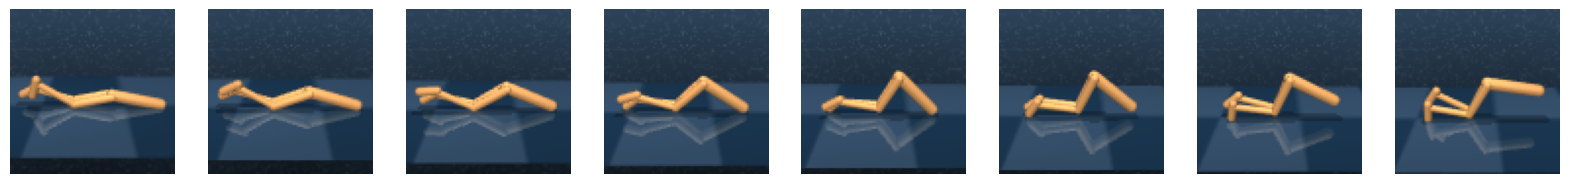

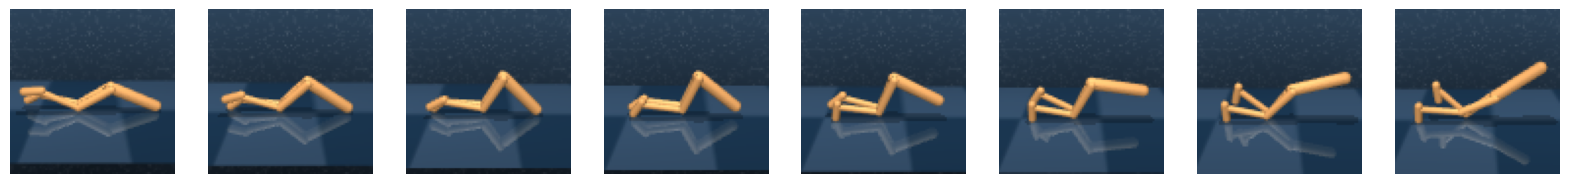

In [5]:
af = fs_a[None] # Just checking that the transition indexing like above 
bf = fs_b[None] # is correct.
draw_clip(af)
draw_clip(bf)

torch.Size([1, 8, 3, 84, 84]) torch.Size([1, 8, 3, 84, 84])


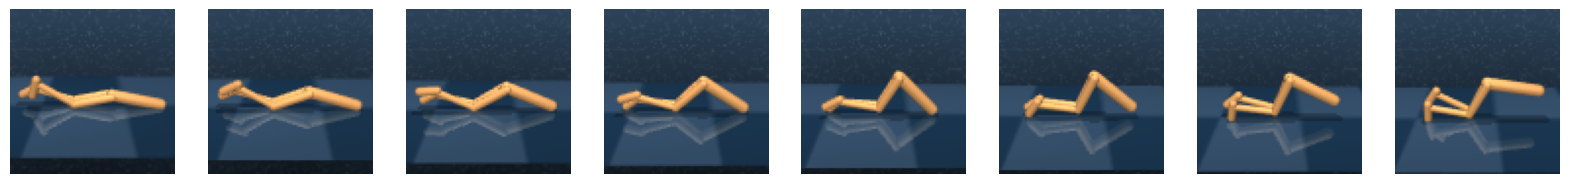

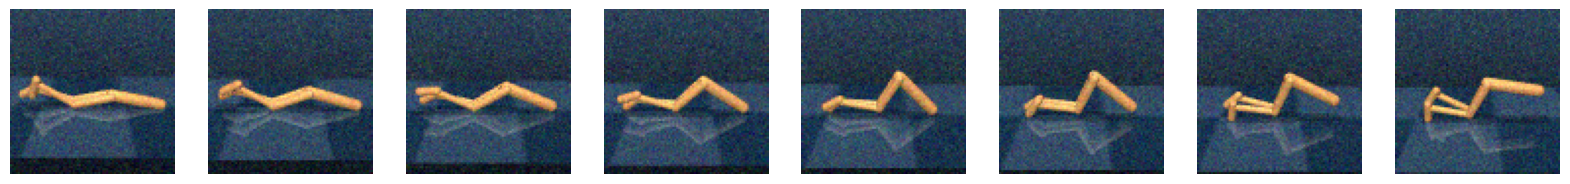

In [6]:
SIG = 0.05
uf = fs_a[None]
pf = perturb_clip(fs_a[None], PERTURBATION_A, SIG)
print(uf.shape, pf.shape)
draw_clip(uf)
draw_clip(pf)

## 2. Single-Level Perturbation Probe

In [7]:
@torch.no_grad()
def perturbation_probe(model: FSQ_V_JEPA | FSQ_VideoVAE, 
                       transition: WindowTransitionProbe, 
                       state_probe: nn.Module, 
                       r2un: R2Score, r2p: R2Score, r2unpt: R2Score, r2ppt: R2Score, 
                       unperturbed, perturbed, action, obs, obs_pt, variance):
    embedding = model(unperturbed)
    perturbed_embedding = model(perturbed)

    obs_pred_unp = state_probe(embedding.reshape(1, -1))
    obs_pred_pert = state_probe(perturbed_embedding.reshape(1, -1))
    r2un.update(obs_pred_unp, obs)
    r2p.update(obs_pred_pert, obs)

    trans = transition(embedding, action)
    perturbed_trans = transition(perturbed_embedding, action)

    pt_obs_pred_unp = state_probe(trans.reshape(1, -1))
    pt_obs_pred_pert = state_probe(perturbed_trans.reshape(1, -1))
    r2unpt.update(pt_obs_pred_unp, obs_pt)
    r2ppt.update(pt_obs_pred_pert, obs_pt)

    trans = trans.round()
    perturbed_trans = perturbed_trans.round()
    changed = (embedding != perturbed_embedding).any(dim=-1)
    changed_transitions = (trans != perturbed_trans).any(dim=-1)

    changed_perc = changed.float().mean()
    changed_transitions_perc = changed_transitions.float().mean()

    static_dist = F.l1_loss(embedding[changed], perturbed_embedding[changed], reduction="none") / (variance ** 0.5)
    transition_dist = F.l1_loss(trans[changed_transitions], perturbed_trans[changed_transitions], reduction="none") / (variance ** 0.5)

    ssim = SSIM(unperturbed[0], perturbed[0])

    return changed_perc, static_dist.mean(dim=(-1, -2)), changed_transitions_perc, transition_dist.mean(dim=(-1, -2)), ssim

def get_obs(obs_orientations, obs_velocities, obs_height):
    obs_height = obs_height[:, None]
    obs = np.concatenate([
        obs_velocities[-1],
        obs_height[-1],
        obs_orientations[-1],
    ], axis=-1)

    return torch.as_tensor(obs, device=DEVICE).unsqueeze(0)

probe_results = {}
ssims = []
for i in range(NUM_SAMPLES):
    frames, actions, _, obs_orientations, obs_velocities, obs_height = testset[i]

    frames_A = frames[:-2][None].to(DEVICE)
    perturbed_frames_A = perturb_clip(frames_A, PERTURBATION_A, SIG).to(DEVICE)
    action_A = actions[:-2][-1][None].to(DEVICE, dtype=torch.float32)
    obs_orientations_A = obs_orientations[:-2]
    obs_velocities_A = obs_velocities[:-2]
    obs_height_A = obs_height[:-2]
    obs_A = get_obs(obs_orientations_A, obs_velocities_A, obs_height_A)

    obs_orientations_B = obs_orientations[2:]
    obs_velocities_B = obs_velocities[2:]
    obs_height_B = obs_height[2:]
    obs_B = get_obs(obs_orientations_B, obs_velocities_B, obs_height_B)



    # perturbed_frames = perturb_clip(frames, PERTURBATION_A, SIG).to(DEVICE)
    # action = actions[-1][None].to(DEVICE, dtype=torch.float32)
    # obs = get_obs(obs_orientations, obs_velocities, obs_height)

    for name, (model, transition, state_probe, variance, r2un, r2p, r2unpt, r2ppt) in model_pairs.items():

        changed_perc, static_dist, changed_transition_perc, transition_dist, ssim = perturbation_probe(
            model, transition, state_probe, 
            r2un, r2p, r2unpt, r2ppt, 
            frames_A, perturbed_frames_A, action_A, obs_A, obs_B, variance)

        if name not in probe_results:
            probe_results[name] = {
                "changed": [],
                "static_dist": [],
                "changed_transition_perc": [],
                "transition_dist": []
            }

        ssims.append(ssim)
        probe_results[name]["changed"].append(changed_perc)
        probe_results[name]["static_dist"].append(static_dist)
        probe_results[name]["changed_transition_perc"].append(changed_transition_perc)
        probe_results[name]["transition_dist"].append(transition_dist)
    
ssims = torch.stack(ssims).mean().item()
print(f"Avg. SSIM={ssims:.2f}")
for name, *_ in model_pairs.items():
    changed = torch.stack(probe_results[name]["changed"]).mean()
    static_dist = torch.stack(probe_results[name]["static_dist"]).mean()
    changed_transition_perc = torch.stack(probe_results[name]["changed_transition_perc"]).mean()
    transition_dist = torch.stack(probe_results[name]["transition_dist"]).mean()

    r2un = model_pairs[name][-4]
    r2p = model_pairs[name][-3]
    r2unpt = model_pairs[name][-2]
    r2ppt = model_pairs[name][-1]
    r2un_value = r2un.compute()
    r2p_value = r2p.compute()
    r2unpt_value = r2unpt.compute()
    r2ppt_value = r2ppt.compute()
    r2un.reset()
    r2p.reset()
    r2unpt.reset()
    r2ppt.reset()


    print(f"{name}")
    print(f"DEBUG R^2 pre transition: unperturbed vs. perturbed = {r2un_value:.2f}, {r2p_value:.2f} \t R^2 post transition: unperturbed vs perturbed = {r2unpt_value:.2f}, {r2ppt_value:.2f}")
    print(f"\t % changed={changed:.2f} \t Chaged distance={static_dist:.2f} \t Delta R^2={r2p_value - r2un_value:.2f} \t % changed post transition={changed_transition_perc:.2f} \t Post transition changed distance={transition_dist:.2f} \t Delta R^2 post transition={r2ppt_value - r2unpt_value:.2f}")

Avg. SSIM=0.49
ae
DEBUG R^2 pre transition: unperturbed vs. perturbed = 0.77, 0.74 	 R^2 post transition: unperturbed vs perturbed = 0.78, 0.76
	 % changed=0.87 	 Chaged distance=0.25 	 Delta R^2=-0.03 	 % changed post transition=0.86 	 Post transition changed distance=0.23 	 Delta R^2 post transition=-0.02
jepa
DEBUG R^2 pre transition: unperturbed vs. perturbed = 0.48, 0.45 	 R^2 post transition: unperturbed vs perturbed = 0.44, 0.44
	 % changed=0.72 	 Chaged distance=0.16 	 Delta R^2=-0.03 	 % changed post transition=0.56 	 Post transition changed distance=0.14 	 Delta R^2 post transition=-0.01


We allow rounding here because it provides a continuity in analysis between the static and the transitioned cases. The rounding is an approximation of the quantized representation.

## Additive-noise sweep

This repeats the perturbation probe over a set of Gaussian-noise standard deviations. Unlike `perturb_clip`, it applies no blur: $x_{\mathrm{pert}}=\operatorname{clip}(x+\epsilon,0,1)$, where $\epsilon\sim\mathcal{N}(0,\sigma^2)$.

In [8]:
def additive_gaussian_noise(x: torch.Tensor, sigma: float) -> torch.Tensor:
    """Perturb a normalized clip with Gaussian noise only (no blur)."""
    return (x + torch.randn_like(x) * sigma).clamp(0, 1)


@torch.no_grad()
def noise_sweep_probe(sigmas, num_samples=NUM_SAMPLES):
    """Run the perturbation probe for each noise sigma and return aggregate metrics."""
    results = {}

    for sigma in sigmas:
        per_model = {
            name: {
                'changed': [], 'static_dist': [],
                'changed_transition_perc': [], 'transition_dist': [],
            }
            for name in model_pairs
        }
        ssims = []

        # The R^2 metrics are stateful, so each sigma starts from a clean state.
        for _, pair in model_pairs.items():
            for metric in pair[-4:]:
                metric.reset()

        for i in range(num_samples):
            frames, actions, _, obs_orientations, obs_velocities, obs_height = testset[i]
            frames_a = frames[:-2][None].to(DEVICE)
            perturbed_frames_a = additive_gaussian_noise(frames_a, sigma)
            action_a = actions[:-2][-1][None].to(DEVICE, dtype=torch.float32)

            obs_a = get_obs(obs_orientations[:-2], obs_velocities[:-2], obs_height[:-2])
            obs_b = get_obs(obs_orientations[2:], obs_velocities[2:], obs_height[2:])

            for name, (model, transition, state_probe, variance, r2un, r2p, r2unpt, r2ppt) in model_pairs.items():
                changed, static_dist, changed_transition, transition_dist, ssim = perturbation_probe(
                    model, transition, state_probe, r2un, r2p, r2unpt, r2ppt,
                    frames_a, perturbed_frames_a, action_a, obs_a, obs_b, variance,
                )
                per_model[name]['changed'].append(changed)
                per_model[name]['static_dist'].append(static_dist)
                per_model[name]['changed_transition_perc'].append(changed_transition)
                per_model[name]['transition_dist'].append(transition_dist)
                ssims.append(ssim)

        results[float(sigma)] = {'ssim': torch.stack(ssims).mean().item()}
        for name, pair in model_pairs.items():
            r2un, r2p, r2unpt, r2ppt = pair[-4:]
            results[float(sigma)][name] = {
                key: torch.stack(values).mean().item()
                for key, values in per_model[name].items()
            }
            results[float(sigma)][name].update({
                'r2_unperturbed': r2un.compute().item(),
                'r2_perturbed': r2p.compute().item(),
                'r2_transition_unperturbed': r2unpt.compute().item(),
                'r2_transition_perturbed': r2ppt.compute().item(),
            })
            results[float(sigma)][name]['delta_r2'] = (
                results[float(sigma)][name]['r2_perturbed'] - results[float(sigma)][name]['r2_unperturbed']
            )
            results[float(sigma)][name]['delta_r2_transition'] = (
                results[float(sigma)][name]['r2_transition_perturbed']
                - results[float(sigma)][name]['r2_transition_unperturbed']
            )
            for metric in (r2un, r2p, r2unpt, r2ppt):
                metric.reset()

        SSIM.reset()

    return results


# Example (kept unevaluated because this runs every model for every sigma):
noise_sweep_results = noise_sweep_probe([0.01, 0.02, 0.05, 0.1], num_samples=NUM_SAMPLES)
noise_sweep_results[0.05]['jepa']


{'changed': 0.719714343547821,
 'static_dist': 0.15901309251785278,
 'changed_transition_perc': 0.5531326532363892,
 'transition_dist': 0.14252719283103943,
 'r2_unperturbed': 0.47977851503251945,
 'r2_perturbed': 0.44976011742573646,
 'r2_transition_unperturbed': 0.44448929134502074,
 'r2_transition_perturbed': 0.4387027703446096,
 'delta_r2': -0.030018397606782987,
 'delta_r2_transition': -0.00578652100041116}

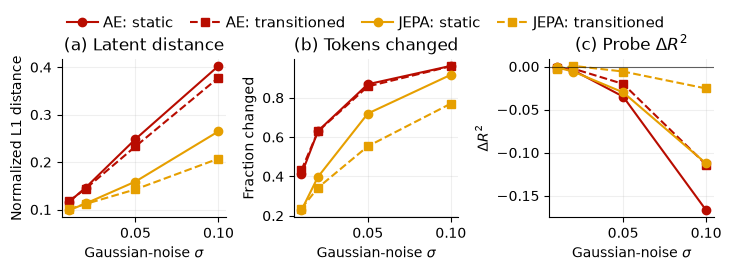

In [25]:
def plot_noise_sweep_results(results):
    """Visualize representation and state-probe sensitivity across noise levels."""
    sigmas = sorted(results)
    model_names = sorted(next(iter(results.values())).keys() - {'ssim'})
    # Okabe--Ito colors with clearly separated grayscale luminance.
    model_colors = {'ae': "#B80C00", 'jepa': '#E69F00'}

    # Compact three-panel figure for a paper column or two-column-width layout.
    # SSIM is omitted here; report it in the caption as input-quality calibration.
    fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.35), sharex=True, layout='constrained')
    ax_distance, ax_changed, ax_r2 = axs

    for name in model_names:
        values = [results[sigma][name] for sigma in sigmas]
        line = ax_distance.plot(sigmas, [v['static_dist'] for v in values], marker='o', color=model_colors[name], label=f'{name.upper()}: static')[0]
        color = line.get_color()
        ax_distance.plot(sigmas, [v['transition_dist'] for v in values], marker='s', ls='--', color=color, label=f'{name.upper()}: transitioned')
        ax_changed.plot(sigmas, [v['changed'] for v in values], marker='o', color=color, label=f'{name.upper()}: static')
        ax_changed.plot(sigmas, [v['changed_transition_perc'] for v in values], marker='s', ls='--', color=color, label=f'{name.upper()}: transitioned')
        ax_r2.plot(sigmas, [v['delta_r2'] for v in values], marker='o', color=color, label=f'{name.upper()}: static')
        ax_r2.plot(sigmas, [v['delta_r2_transition'] for v in values], marker='s', ls='--', color=color, label=f'{name.upper()}: transitioned')

    ax_distance.set(title='(a) Latent distance', ylabel='Normalized L1 distance')
    ax_changed.set(title='(b) Tokens changed', ylabel='Fraction changed')
    ax_r2.axhline(0, color='black', lw=0.8, alpha=0.6)
    ax_r2.set(title=r'(c) Probe $\Delta R^2$', ylabel=r'$\Delta R^2$')

    for ax in axs:
        ax.set(xlabel=r'Gaussian-noise $\sigma$')
        ax.grid(alpha=0.2)
        ax.spines[['top', 'right']].set_visible(False)

    handles, labels = ax_distance.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncols=4, frameon=False,
               bbox_to_anchor=(0.5, 1.12), fontsize=11, columnspacing=1.1, handletextpad=0.35)

    return fig, axs


fig, axs = plot_noise_sweep_results(noise_sweep_results)


In [26]:
fig.savefig("../pics/visual_pert_probe_walker_rn1.pdf", format="pdf", bbox_inches="tight")

## 3. Noise-Sweep Plot with Absolute $R^2$ Annotations

findfont: Failed to find font weight semibold, now using 700.


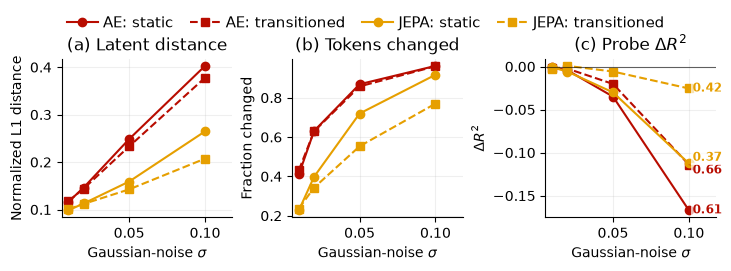

In [9]:
def plot_noise_sweep_results_with_abs_r2(results, label_fmt="{:.2f}"):
    """Visualize representation and state-probe sensitivity across noise levels,
    annotating the absolute R^2 value at the largest noise level without text overlap."""
    sigmas = sorted(results)
    model_names = sorted(next(iter(results.values())).keys() - {'ssim'})
    # Okabe--Ito colors with clearly separated grayscale luminance.
    model_colors = {'ae': "#B80C00", 'jepa': '#E69F00'}

    fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.35), sharex=True, layout='constrained')
    ax_distance, ax_changed, ax_r2 = axs

    for name in model_names:
        values = [results[sigma][name] for sigma in sigmas]
        line = ax_distance.plot(sigmas, [v['static_dist'] for v in values], marker='o', color=model_colors[name], label=f'{name.upper()}: static')[0]
        color = line.get_color()
        ax_distance.plot(sigmas, [v['transition_dist'] for v in values], marker='s', ls='--', color=color, label=f'{name.upper()}: transitioned')
        ax_changed.plot(sigmas, [v['changed'] for v in values], marker='o', color=color, label=f'{name.upper()}: static')
        ax_changed.plot(sigmas, [v['changed_transition_perc'] for v in values], marker='s', ls='--', color=color, label=f'{name.upper()}: transitioned')
        ax_r2.plot(sigmas, [v['delta_r2'] for v in values], marker='o', color=color, label=f'{name.upper()}: static')
        ax_r2.plot(sigmas, [v['delta_r2_transition'] for v in values], marker='s', ls='--', color=color, label=f'{name.upper()}: transitioned')

    ax_distance.set(title='(a) Latent distance', ylabel='Normalized L1 distance')
    ax_changed.set(title='(b) Tokens changed', ylabel='Fraction changed')
    ax_r2.axhline(0, color='black', lw=0.8, alpha=0.6)
    ax_r2.set(title=r'(c) Probe $\Delta R^2$', ylabel=r'$\Delta R^2$')

    for ax in axs:
        ax.set(xlabel=r'Gaussian-noise $\sigma$')
        ax.grid(alpha=0.2)
        ax.spines[['top', 'right']].set_visible(False)

    # --- Annotate absolute R^2 at the largest noise level on ax_r2 ---
    max_sigma = max(sigmas)
    annotations = []
    for name in model_names:
        color = model_colors[name]
        v_max = results[max_sigma][name]
        annotations.append({
            'name': name,
            'probe_type': 'static',
            'x': max_sigma,
            'y': v_max['delta_r2'],
            'abs_r2': v_max['r2_perturbed'],
            'color': color,
        })
        annotations.append({
            'name': name,
            'probe_type': 'transitioned',
            'x': max_sigma,
            'y': v_max['delta_r2_transition'],
            'abs_r2': v_max['r2_transition_perturbed'],
            'color': color,
        })

    # Sort annotations by y-position (delta_r2)
    annotations.sort(key=lambda item: item['y'])

    # Determine vertical spacing to prevent overlap
    y_min, y_max = ax_r2.get_ylim()
    y_span = y_max - y_min
    min_gap = 0.08 * y_span  # minimum clearance between label centers
    adjusted_y = [item['y'] for item in annotations]

    # Iterative 1D vertical repulsion to resolve overlaps
    for _ in range(50):
        for i in range(len(adjusted_y) - 1):
            gap = adjusted_y[i + 1] - adjusted_y[i]
            if gap < min_gap:
                overlap = min_gap - gap
                adjusted_y[i] -= overlap / 2.0
                adjusted_y[i + 1] += overlap / 2.0

    # Ensure annotations remain within y-limits with padding
    if adjusted_y[0] < y_min + 0.03 * y_span:
        ax_r2.set_ylim(bottom=adjusted_y[0] - 0.05 * y_span)
    if adjusted_y[-1] > y_max - 0.03 * y_span:
        ax_r2.set_ylim(top=adjusted_y[-1] + 0.05 * y_span)

    # Horizontal offset to place labels just to the right of the markers
    x_min, x_max = ax_r2.get_xlim()
    x_span = x_max - x_min
    x_offset = 0.025 * x_span
    # Expand xlim slightly so annotations fit comfortably without clipping
    ax_r2.set_xlim(x_min, max_sigma + 0.18 * x_span)

    # Render each absolute R^2 annotation
    for item, y_adj in zip(annotations, adjusted_y):
        text = label_fmt.format(item['abs_r2'])
        was_displaced = abs(y_adj - item['y']) > (0.015 * y_span)
        ax_r2.annotate(
            text,
            xy=(item['x'], item['y']),
            xytext=(item['x'] + x_offset, y_adj),
            textcoords='data',
            va='center',
            ha='left',
            fontsize=8.5,
            color=item['color'],
            fontweight='semibold',
            bbox=dict(boxstyle='square,pad=0.1', facecolor='white', edgecolor='none', alpha=0.7),
            arrowprops=dict(
                arrowstyle='-',
                color=item['color'],
                lw=0.6,
                alpha=0.5,
                shrinkA=2,
                shrinkB=2,
            ) if was_displaced else None,
        )

    handles, labels = ax_distance.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncols=4, frameon=False,
               bbox_to_anchor=(0.5, 1.12), fontsize=11, columnspacing=1.1, handletextpad=0.35)

    return fig, axs


fig, axs = plot_noise_sweep_results_with_abs_r2(noise_sweep_results)


In [10]:
fig.savefig("../pics/visual_pert_probe_walker_rn1_2.pdf", format="pdf", bbox_inches="tight")